# Ma session d’entraînement — lancement volontaire

**Session terminée et vérifiée le 7 novembre 2026 — lancement désactivé.**

Les cellules de suivi lisent les résultats existants. Aucune nouvelle session nécessaire.

Objectif : lancer et suivre toi-même un CNN, puis revenir avec ses sorties.
Recette fixée : graine 42 depuis zéro, **30 époques maximum**, **patience 5**,
AdamW à 0,001, sélection par macro-F1 de validation par morceau. Amélioration
strictement positive (seuil 0) ; en cas d’égalité, garder la première époque.
Le meilleur checkpoint est restauré. Budget d’apprentissage : deux heures.

La V1 utilisait patience 3 ; cette session teste une règle différente.
Elle n’entraîne pas le ViT gelé par époques. Aucun gain n’est promis et aucun
test V1 n’est consulté pendant cet entraînement complémentaire.

**« Tout exécuter » est sans entraînement par défaut.** Le lancement nécessite
de changer `LANCER = False` en `True` dans une cellule dédiée. Ensuite, remettre
la valeur à `False`. Le processus écrit ses sorties sur disque et continue si
tu fermes ce notebook ; arrêter ou mettre le PC en veille interrompt le calcul.

Choisir le noyau **Music genres — session utilisateur**.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, subprocess
from importlib.metadata import version
from IPython.display import display, Markdown
start = Path(os.environ.get("MUSIC_GENRE_ROOT", Path.cwd())).resolve()
ROOT = next((p for p in (start, *start.parents) if (p/"reports/USER_SESSION_READY.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Ouvrir le notebook depuis le projet.")
expected_python = (ROOT/".venv-notebook/Scripts/python.exe").resolve()
if Path(sys.executable).resolve() != expected_python:
    raise RuntimeError("Choisir le noyau Music genres — session utilisateur (.venv-notebook).")
ready = json.loads((ROOT/"reports/USER_SESSION_READY.json").read_text(encoding="utf-8"))
for relative, expected in ready["source_sha256"].items():
    if hashlib.sha256((ROOT/relative).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Source ou recette modifiée : {relative}. Faire vérifier avant lancement.")
for name, expected in ready["versions"].items():
    assert version(name) == expected, f"Version modifiée : {name}"
config = json.loads((ROOT/"configs/cnn_user.json").read_text(encoding="utf-8"))
import torch
print("Python :", sys.executable)
print("PyTorch :", torch.__version__, "| CUDA disponible :", torch.cuda.is_available())
print("Exécution prévue : CPU,", config["threads"], "threads.")
print("Petit essai avec pause/reprise déjà vérifié :", ready["smoke_resume_verified"])
display({k: config[k] for k in ["seed","max_epochs","patience","learning_rate","weight_decay","batch_size","budget_seconds"]})

Python : E:\projet\vision transformer\.venv-notebook\Scripts\python.exe
PyTorch : 2.14.1+cpu | CUDA disponible : False
Exécution prévue : CPU, 4 threads.
Petit essai avec pause/reprise déjà vérifié : True


{'seed': 42,
 'max_epochs': 30,
 'patience': 5,
 'learning_rate': 0.001,
 'weight_decay': 0.0001,
 'batch_size': 16,
 'budget_seconds': 7200}

## 1. Temps et fichiers à prévoir

Prévoir environ **35 à 80 minutes au plafond de 30 époques**, moins si l’arrêt
anticipé intervient. C’est une estimation fondée sur les époques complètes V1,
avec une marge, pas une durée garantie. La vérification du cache et l’export
ajoutent du temps ; le budget d’apprentissage est de deux heures.

Les données sont déjà disponibles : 6 299 morceaux train et 780 validation.
Le petit essai technique portait seulement sur 16 morceaux par partition ;
ses scores ne représentent pas la qualité du modèle. Le lancement complet
emploiera toute la cohorte train/validation prévue.

Brancher l’ordinateur et éviter la veille pendant le calcul. Conserver le dossier
`runs/cnn_user-...`, ses checkpoints, les prédictions et les journaux.

In [2]:
print("Estimation avec marge :", round(ready["estimated_30_epochs_with_margin_seconds"]/60), "minutes")
print("Compte rendu de préparation : reports/USER_SESSION_READY.json")
print("État du lancement : reports/USER_TRAINING_JOB.json")
print("Dernier dossier : reports/latest_cnn_user_training.json")

Estimation avec marge : 74 minutes
Compte rendu de préparation : reports/USER_SESSION_READY.json
État du lancement : reports/USER_TRAINING_JOB.json
Dernier dossier : reports/latest_cnn_user_training.json


## 2. Lancer volontairement

Une seule session complète est autorisée par le lanceur. Il vérifie les processus
existants et les entraîneurs se protègent par verrou. Pour reprendre après arrêt,
utiliser `REPRENDRE = True` avec `LANCER = True` ; la configuration, les données,
le code et l’environnement doivent rester identiques.

Une époque incomplète n’est pas conservée. La reprise repart du dernier checkpoint
complet avec optimiseur, état aléatoire, historique et compteur de patience.

In [3]:
LANCER = False
REPRENDRE = False

if LANCER:
    command = [str(expected_python), str(ROOT/"scripts/user_session.py"), "--launch"]
    if REPRENDRE:
        command.append("--resume")
    completed = subprocess.run(command, cwd=ROOT, text=True, capture_output=True)
    print(completed.stdout)
    if completed.returncode:
        raise RuntimeError(completed.stderr)
    print("Le superviseur a été demandé. Vérifier la cellule d’état ci-dessous.")
else:
    print("Aucun entraînement lancé. Passer LANCER à True uniquement quand tu es prêt.")

Aucun entraînement lancé. Passer LANCER à True uniquement quand tu es prêt.


## 3. Vérifier l’avancement quand tu le souhaites

Réexécuter cette cellule, sans boucle d’attente automatique. `starting` et
`running` signifient en cours ; `complete` confirme la fin ; `failed`,
`interrupted`, `paused` ou `budget_exhausted` demandent une lecture du journal.
Un arrêt par budget n’est pas une expérience complète au plafond prévu.

In [4]:
status = subprocess.run([str(expected_python), str(ROOT/"scripts/user_session.py")],
                        cwd=ROOT, text=True, capture_output=True)
print(status.stdout)
if status.returncode:
    print(status.stderr)
pointer = ROOT/"reports/latest_cnn_user_training.json"
progress = None
folder = None
if pointer.exists():
    folder = ROOT/json.loads(pointer.read_text(encoding="utf-8"))["folder"]
    path = folder/"progress.json"
    if path.exists():
        progress = json.loads(path.read_text(encoding="utf-8"))
        display({k:v for k,v in progress.items() if k != "history"})
    print("Dossier durable :", folder)
else:
    print("Pas encore de dossier d’entraînement complet.")

{
  "status": "complete",
  "started_at": "2026-11-07T07:29:41.932982+00:00",
  "supervisor": {
    "pid": 59552,
    "created": 1794036581.6598115
  },
  "command": [
    "E:\\projet\\vision transformer\\.venv-notebook\\Scripts\\python.exe",
    "-u",
    "E:\\projet\\vision transformer\\scripts\\train_user_cnn.py"
  ],
  "smoke": false,
  "test_evaluated": false,
  "training_process": {
    "pid": 58696,
    "created": 1794036581.9386156
  },
  "exit_code": 0,
  "finished_at": "2026-11-07T08:18:34.393516+00:00",
  "folder": "runs/cnn_user-20261107T073012932719Z"
}



{'status': 'complete',
 'selected_epoch': 26,
 'stop_reason': 'max_epochs',
 'validation': {'tracks': 780,
  'macro_f1': 0.570680563874727,
  'accuracy': 0.5782051282051283,
  'confusion_matrix': [[64, 4, 0, 8, 17, 1, 3, 2],
   [7, 62, 2, 0, 20, 1, 2, 6],
   [2, 1, 60, 1, 14, 0, 14, 7],
   [27, 0, 1, 65, 1, 2, 3, 1],
   [5, 11, 5, 0, 59, 0, 6, 7],
   [11, 3, 1, 3, 11, 58, 6, 5],
   [19, 14, 11, 5, 15, 3, 10, 17],
   [1, 6, 0, 0, 8, 1, 8, 73]],
  'per_class': {'Electronic': {'precision': 0.47058823529411764,
    'recall': 0.6464646464646465,
    'f1-score': 0.5446808510638298,
    'support': 99.0},
   'Experimental': {'precision': 0.6138613861386139,
    'recall': 0.62,
    'f1-score': 0.6169154228855721,
    'support': 100.0},
   'Folk': {'precision': 0.75,
    'recall': 0.6060606060606061,
    'f1-score': 0.6703910614525139,
    'support': 99.0},
   'Hip-Hop': {'precision': 0.7926829268292683,
    'recall': 0.65,
    'f1-score': 0.7142857142857143,
    'support': 100.0},
   'Instrumen

Dossier durable : E:\projet\vision transformer\runs\cnn_user-20261107T073012932719Z


## 4. Lire les courbes et les résultats disponibles

Les courbes affichent uniquement les époques terminées. L’accuracy et la macro-F1
sont calculées par morceau sur validation, la perte train par fenêtre.
Une hausse de la perte ou un plateau ne justifie pas de changer rétroactivement
la patience. La graine unique ne suffit pas à conclure à une supériorité sur
la moyenne des trois CNN V1.

,Époque,Perte train,Macro-F1 validation,Accuracy validation
0,1,1.8472,0.3165,0.3603
1,2,1.6544,0.3978,0.4295
2,3,1.5495,0.4370,0.4615
3,4,1.4938,0.4637,0.4897
4,5,1.4529,0.4425,0.4654
5,6,1.4259,0.4954,0.5218
6,7,1.3945,0.5132,0.5321
7,8,1.3709,0.5113,0.5321
8,9,1.3449,0.5301,0.5577
9,10,1.3221,0.5270,0.5397


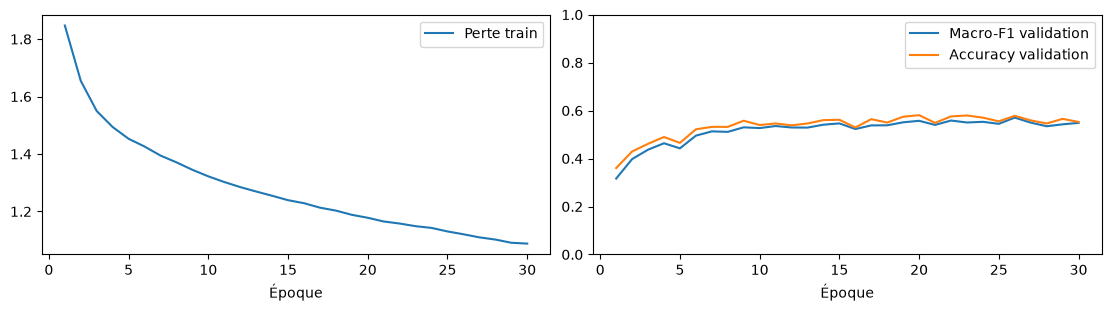

{'status': 'complete',
 'stop_reason': 'max_epochs',
 'epochs_completed': 30,
 'selected_epoch': 26,
 'track_counts': {'train': 6299, 'validation': 780},
 'validation': {'tracks': 780,
  'macro_f1': 0.570680563874727,
  'accuracy': 0.5782051282051283,
  'confusion_matrix': [[64, 4, 0, 8, 17, 1, 3, 2],
   [7, 62, 2, 0, 20, 1, 2, 6],
   [2, 1, 60, 1, 14, 0, 14, 7],
   [27, 0, 1, 65, 1, 2, 3, 1],
   [5, 11, 5, 0, 59, 0, 6, 7],
   [11, 3, 1, 3, 11, 58, 6, 5],
   [19, 14, 11, 5, 15, 3, 10, 17],
   [1, 6, 0, 0, 8, 1, 8, 73]],
  'per_class': {'Electronic': {'precision': 0.47058823529411764,
    'recall': 0.6464646464646465,
    'f1-score': 0.5446808510638298,
    'support': 99.0},
   'Experimental': {'precision': 0.6138613861386139,
    'recall': 0.62,
    'f1-score': 0.6169154228855721,
    'support': 100.0},
   'Folk': {'precision': 0.75,
    'recall': 0.6060606060606061,
    'f1-score': 0.6703910614525139,
    'support': 99.0},
   'Hip-Hop': {'precision': 0.7926829268292683,
    'recall': 

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
report = None
history = progress.get("history", []) if progress else []
if folder and (folder/"report.json").exists():
    report = json.loads((folder/"report.json").read_text(encoding="utf-8"))
    history = report["history"]
if history:
    frame = pd.DataFrame([{"Époque": h["epoch"], "Perte train": h["training_window_loss"],
                            "Macro-F1 validation": h["validation"]["macro_f1"],
                            "Accuracy validation": h["validation"]["accuracy"]} for h in history])
    display(frame.round(4))
    fig, axes = plt.subplots(1,2,figsize=(11,3),layout="constrained")
    frame.plot(x="Époque",y="Perte train",ax=axes[0])
    frame.plot(x="Époque",y=["Macro-F1 validation","Accuracy validation"],ax=axes[1])
    axes[1].set_ylim(0,1)
    plt.show()
else:
    print("Aucune époque complète de la session utilisateur pour l’instant.")
if report:
    display({k:report[k] for k in ["status","stop_reason","epochs_completed","selected_epoch","track_counts","validation","test_evaluated"]})

## 5. Vérification finale réalisée

Le 7 novembre, les empreintes, la cohorte, le motif d’arrêt, les meilleurs poids
et les métriques ont été contrôlés. Les résultats sont intégrés ci-dessous et
au parcours principal. La procédure de lancement reste disponible à titre de
reproduction ; ne pas relancer pour consulter les résultats.


## Session utilisateur vérifiée — 7 novembre 2026

Le CNN graine 42 a terminé **30 époques en 48 min 52 s**. Le modèle de
**l’époque 26** est conservé : macro-F1 validation **0,5707**, accuracy **57,82 %**
(451/780 morceaux). Train : macro-F1 0,6298, accuracy 63,30 %.

L’arrêt vient du plafond de trente époques ; quatre époques sans amélioration
ne suffisent pas à déclencher la patience cinq. La dernière époque atteint
seulement 0,5487 : conserver les meilleurs poids est utile.

Face au CNN V1 de même graine, le gain validation est de **2,42 points de F1**.
Les dix-huit premières époques reproduisent les mêmes pertes et métriques.
La patience trois arrêtait l’ancien run avant les améliorations tardives.
Plafond et patience changent ensemble ; une graine et une validation utilisée
pour sélectionner ne prouvent pas un gain de généralisation.

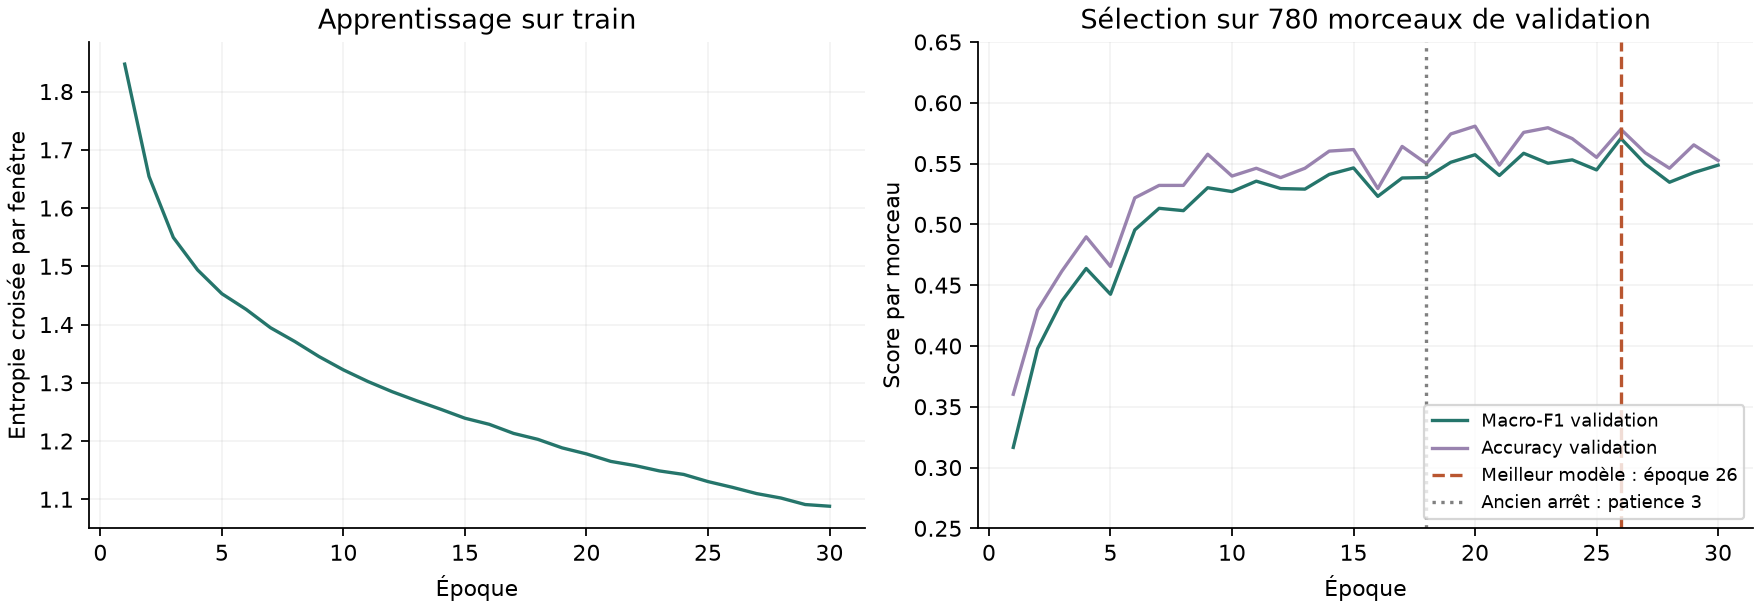

Les poids exportés reproduisent exactement les probabilités validation.
L’inférence a été rejouée sur tous les morceaux train/validation, avec agrégation
et métriques recalculées séparément. **Aucun audio test chargé** ; la V1 reste figée.
Pop demeure faible : 10/94 corrects, F1 0,1370. Aucun entraînement à relancer.

[Résultats détaillés](../reports/SESSION_UTILISATEUR.md) ·
[Preuve de contrôle](../reports/USER_SESSION_CHECK.json) ·
[Conclusion générale](../docs/CONCLUSION_PROJET.md)

Instantané vérifié du run `cnn_user-20261107T073012932719Z` ; empreinte du rapport :
`f748e20f17aaefa3c4717dd70c583ca057d99832823f134e04499a1f3eeef834`.
